# 03 · Fenómeno 1 (obligatorio): ¿qué significa "calidad" en estos datos?

¿Cuáles variables de calidad miden una condición del rollo y cuáles son **reglas**
aplicadas a otras columnas? Genera las figuras 1 y 2 del documento.

In [1]:
import sys
sys.path.insert(0, "..")  # para importar src/

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.poblacion import preparar, poblacion
from src.calidad import familia, reglas_tolerancia, concordancia_regla
from src.visualizacion import estilo, guardar, AZUL, NARANJA, GRIS

df, d = preparar()
p = poblacion(df)
estilo()

## 1. Las capas de "calidad": dictamen, resolución, defectos

In [3]:
print("Dictamen (todos los rollos):")
print(df["Dictamen"].value_counts(dropna=False).to_string())
print(f"\n% de rollos con ≥1 defecto: {100 * df['def_cualquiera'].mean():.1f} %")
print(f"% RETENIDO: {100 * df['Dictamen'].eq('RETENIDO').mean():.1f} %")

# ¿El dictamen del rollo se deriva de los defectos?
ret_def = d.loc[d["Dictamen"].eq("RETENIDO"), "Material Salida"].unique()
rollo_ret = df["Dictamen"].eq("RETENIDO")
derivado = rollo_ret == df["Material Salida"].isin(ret_def)
print(f"Concordancia 'rollo RETENIDO ⇔ algún defecto RETENIDO': {100 * derivado.mean():.2f} %")

Dictamen (todos los rollos):
Dictamen
RETENIDO    75182
ACEPTADO    74552

% de rollos con ≥1 defecto: 88.5 %
% RETENIDO: 50.2 %


Concordancia 'rollo RETENIDO ⇔ algún defecto RETENIDO': 99.89 %


## 2. Prevalencia y % automático por defecto (fig. 1)


% de registros automáticos (todos): 76.0 %
% de registros que son reglas dimensionales o térmicas: 67.5 %

Top 12 defectos:
                                  % rollos  automatico                                 fam
Defecto                                                                                   
ESPESOR (+/-)                       44.186       1.000  dimensional (regla vs. tolerancia)
TEMPERATURA DE ENROLLADO (-)        31.012       1.000      térmico (regla vs. tolerancia)
TEMPERATURA DE ACABADO (+/-)        19.153       1.000      térmico (regla vs. tolerancia)
ANCHO (+/-)                         14.265       1.000  dimensional (regla vs. tolerancia)
ÓXIDO ROJO                          12.918       0.000                   superficie: óxido
OXIDO POR TEMPERATURA               11.801       0.134                   superficie: óxido
TEMPERATURA DE ENROLLADO (+/-)       9.663       1.000      térmico (regla vs. tolerancia)
INCUMPLIMIENTO ESP. BARRA TRANSF     6.825       1.000  

/Users/macbookpro/Desktop/ternium/outputs/figuras/fig1_capas_calidad.png


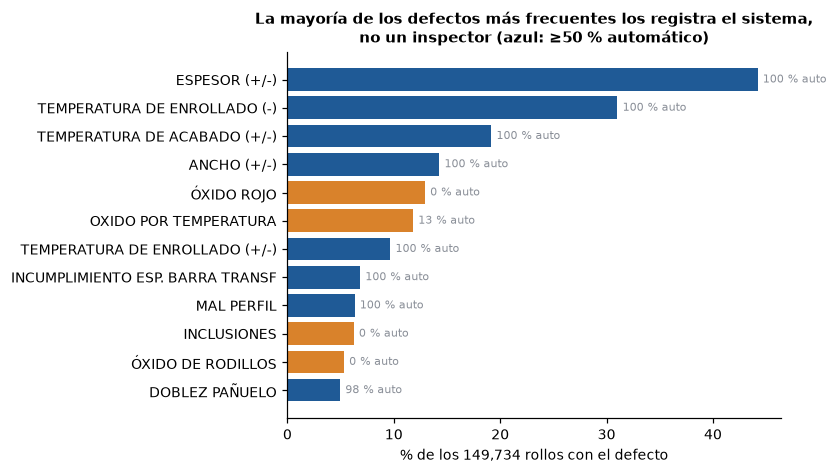

In [4]:
d["fam"] = familia(d["Defecto"])
top = (d.groupby("Defecto")
       .agg(registros=("Defecto", "size"),
            rollos=("Material Salida", "nunique"),
            automatico=("Registro Automatico", "mean"),
            fam=("fam", "first"))
       .sort_values("rollos", ascending=False))
top["% rollos"] = 100 * top["rollos"] / len(df)
print(f"\n% de registros automáticos (todos): {100 * d['Registro Automatico'].mean():.1f} %")
reglas_dim_term = top["fam"].str.contains("regla vs. tolerancia")
print(f"% de registros que son reglas dimensionales o térmicas: "
      f"{100 * top.loc[reglas_dim_term, 'registros'].sum() / len(d):.1f} %")
print("\nTop 12 defectos:")
print(top.head(12)[["% rollos", "automatico", "fam"]].round(3).to_string())

t12 = top.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
colores = [AZUL if a >= 0.5 else NARANJA for a in t12["automatico"]]
ax.barh(t12.index, t12["% rollos"], color=colores)
for i, (pct, auto) in enumerate(zip(t12["% rollos"], t12["automatico"])):
    ax.text(pct + 0.5, i, f"{auto * 100:.0f} % auto", va="center", fontsize=7.5, color=GRIS)
ax.set_xlabel("% de los 149,734 rollos con el defecto")
ax.set_title("La mayoría de los defectos más frecuentes los registra el sistema,\n"
             "no un inspector (azul: ≥50 % automático)")
print(guardar(fig, "fig1_capas_calidad"))

## 3. ¿Se pueden reconstruir las reglas con el resumen por rollo? (fig. 2)


Reconstrucción de reglas (con el RESUMEN por rollo):
                                                   regla  % rollos con etiqueta  % rollos que cumplen la regla  P(etiqueta | regla)  P(etiqueta | no regla)  % de etiquetas explicadas por la regla
etiqueta                                                                                                                                                                                           
def_espesor         espesor promedio fuera de [mín, máx]                 44.186                          0.302                0.024                   0.443                                   0.017
def_ancho             ancho promedio fuera de [mín, máx]                 14.265                          0.496                0.981                   0.138                                   3.413
def_te_menos               temp. enrollado real < mínimo                 31.012                          1.525                0.419                   0.308       

/Users/macbookpro/Desktop/ternium/outputs/figuras/fig2_reconstruccion_reglas.png


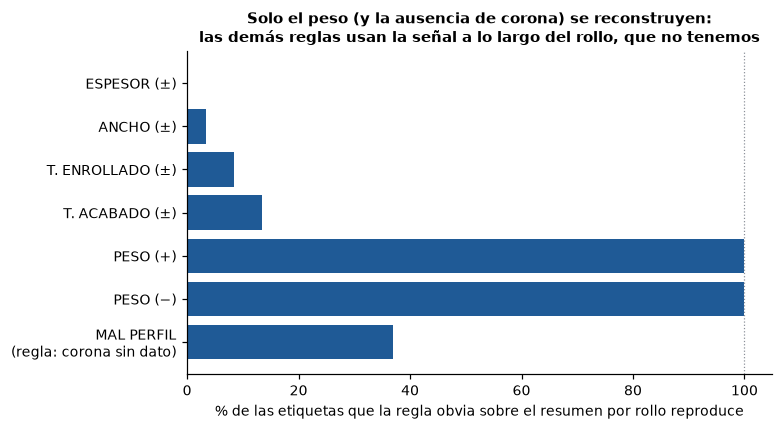

In [5]:
filas = []
for bandera, (desc, regla) in reglas_tolerancia(df).items():
    c = concordancia_regla(df[bandera], regla)
    filas.append({"etiqueta": bandera, "regla": desc, **c})
rec = pd.DataFrame(filas).set_index("etiqueta")
print("\nReconstrucción de reglas (con el RESUMEN por rollo):")
print(rec.round(3).to_string())

nombres = {
    "def_espesor": "ESPESOR (±)", "def_ancho": "ANCHO (±)", "def_te_pm": "T. ENROLLADO (±)",
    "def_ta_pm": "T. ACABADO (±)", "def_peso_mas": "PESO (+)", "def_peso_menos": "PESO (−)",
    "def_mal_perfil": "MAL PERFIL\n(regla: corona sin dato)",
}
sel = rec.loc[list(nombres)].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh([nombres[i] for i in sel.index], sel["% de etiquetas explicadas por la regla"], color=AZUL)
ax.axvline(100, color=GRIS, lw=0.8, ls=":")
ax.set_xlabel("% de las etiquetas que la regla obvia sobre el resumen por rollo reproduce")
ax.set_title("Solo el peso (y la ausencia de corona) se reconstruyen:\n"
             "las demás reglas usan la señal a lo largo del rollo, que no tenemos")
print(guardar(fig, "fig2_reconstruccion_reglas"))

## 4. MAL PERFIL codifica la ausencia del dato

In [6]:
mp_sin_dato = d.loc[d["Defecto"].eq("MAL PERFIL"), "Observaciones"].astype(str).str.contains(
    "No se dispone", case=False, na=False)
print(f"\n% de registros MAL PERFIL con 'No se dispone de datos de corona y cuña': "
      f"{100 * mp_sin_dato.mean():.1f} %")
sin_corona = df["Corona Salida"].isna()
print(f"P(MAL PERFIL | corona faltante) = {df.loc[sin_corona, 'def_mal_perfil'].mean():.3f} | "
      f"P(MAL PERFIL | corona presente) = {df.loc[~sin_corona, 'def_mal_perfil'].mean():.3f}")


% de registros MAL PERFIL con 'No se dispone de datos de corona y cuña': 37.0 %
P(MAL PERFIL | corona faltante) = 0.994 | P(MAL PERFIL | corona presente) = 0.041


## 5. La retención es casi siempre automática

In [7]:
# Causas de retención = defectos del rollo cuyo propio dictamen es RETENIDO
ret_ids = df.loc[rollo_ret, "Material Salida"]
d_ret = d[d["Dictamen"].eq("RETENIDO") & d["Material Salida"].isin(ret_ids)]
solo_auto = d_ret.groupby("Material Salida")["Registro Automatico"].min()
print(f"\n% de rollos RETENIDOS cuyas causas de retención son TODAS automáticas: "
      f"{100 * (solo_auto == 1).mean():.1f} %")
esp_causa = d_ret["Defecto"].eq("ESPESOR (+/-)").groupby(d_ret["Material Salida"]).max()
print(f"% de retenidos con ESPESOR (±) entre las causas: {100 * esp_causa.mean():.1f} %")


% de rollos RETENIDOS cuyas causas de retención son TODAS automáticas: 81.0 %
% de retenidos con ESPESOR (±) entre las causas: 60.2 %


## 6. En la población de estudio

In [8]:
print(f"\nPoblación SKP Pesquería: ≥1 defecto {100 * p['def_cualquiera'].mean():.1f} % | "
      f"RETENIDO {100 * p['Dictamen'].eq('RETENIDO').mean():.1f} % | "
      f"ESPESOR (±) {100 * p['def_espesor'].mean():.1f} %")
print(f"Línea de origen PROVEEDOR en INCLUSIONES: "
      f"{100 * d.loc[d['Defecto'].eq('INCLUSIONES'), 'Linea Origen'].eq('PROVEEDOR').mean():.0f} %")


Población SKP Pesquería: ≥1 defecto 96.1 % | RETENIDO 59.1 % | ESPESOR (±) 72.3 %
Línea de origen PROVEEDOR en INCLUSIONES: 99 %
